# 기울기 소실 실습

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SuminHan/book-ml/blob/main/slides/v2/ml1/week09/vanishing_gradient/lab/vanishing_gradient.ipynb)

역전파는 층마다 곱한다. 시그모이드와 ReLU, 그리고 초기화를 직접 비교한다.

- **파트 1**: numpy: 기울기 곱하기, 초기화별 층 출력 크기
- **파트 2**: PyTorch 10층 신경망 (MNIST): 층별 기울기 재기
- **파트 3**: 1에폭 학습 정답률: 시그모이드 · ReLU · Leaky ReLU · GELU

`None` 으로 비워 둔 `TODO` 줄을 채우고 셀을 차례로 실행하세요.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

## 파트 1. 곱하기의 힘

시그모이드 기울기의 최댓값 0.25 를 층 수만큼 곱하면?

In [ ]:
for layers in [1, 5, 10, 20]:
    print(f"{layers:2d} layers: 0.25^{layers} = {0.25 ** layers:.2e}")

def layer_stds(scale, n=256, layers=10, seed=0):
    rng = np.random.default_rng(seed)
    h = rng.normal(0, 1, (1000, n))
    stds = []
    for _ in range(layers):
        W = rng.normal(0, scale, (n, n))
        h = None  # TODO: one ReLU layer
        stds.append(h.std())
    return stds

n = 256
for name, scale in [("0.01", 0.01), ("1", 1.0), ("Xavier", np.sqrt(1 / n)), ("He", None)]:  # TODO: He scale
    s = layer_stds(scale, n)
    plt.semilogy(range(1, 11), s, "o-", label=name)
    print(f"{name:6s}: layer 1 {s[0]:.3g}   layer 10 {s[-1]:.3g}")
plt.xlabel("layer"); plt.ylabel("std of outputs"); plt.legend(); plt.show()

**예상 결과**

```
 1 layers: 0.25^1 = 2.50e-01
 5 layers: 0.25^5 = 9.77e-04
10 layers: 0.25^10 = 9.54e-07
20 layers: 0.25^20 = 9.09e-13
0.01  : layer 1 0.094   layer 10 3.04e-10
1     : layer 1 9.4   layer 10 3.04e+10
Xavier: layer 1 0.588   layer 10 0.0276
He    : layer 1 0.831   layer 10 0.883
```

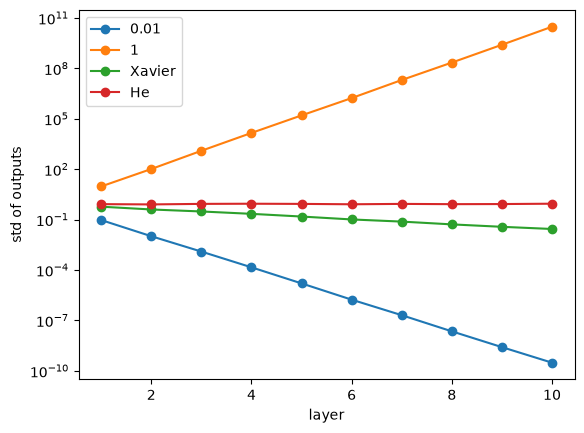

## 파트 2. MNIST 10층 신경망의 층별 기울기

처음 실행하면 MNIST (약 11MB) 를 내려받는다. 학습 전에 배치 512장으로 한 번 역전파하고, 층마다 가중치 기울기의 평균 절댓값을 잰다.

In [ ]:
import torch, torch.nn as nn
from torchvision import datasets
tr = datasets.MNIST("data", train=True, download=True); te = datasets.MNIST("data", train=False, download=True)
Xtr = tr.data.reshape(-1, 784).float() / 255; ytr = tr.targets
Xte = te.data.reshape(-1, 784).float() / 255; yte = te.targets

def make_net(act, depth=10, width=64):
    layers, d = [], 784
    for _ in range(depth):
        lin = nn.Linear(d, width)
        if isinstance(act, nn.Sigmoid):
            nn.init.xavier_normal_(lin.weight)
        else:
            nn.init.kaiming_normal_(lin.weight, nonlinearity="relu")
        nn.init.zeros_(lin.bias)
        layers += [lin, act]; d = width
    layers.append(nn.Linear(d, 10))
    return nn.Sequential(*layers)

def layer_grads(net, X, y):
    net.zero_grad()
    nn.functional.cross_entropy(net(X), y).backward()
    return None  # TODO: mean |grad| of each hidden Linear layer

torch.manual_seed(0)
for name, act in [("sigmoid", nn.Sigmoid()), ("relu", nn.ReLU())]:
    g = layer_grads(make_net(act), Xtr[:512], ytr[:512])
    plt.semilogy(range(1, 11), g, "o-", label=name)
    print(f"{name:7s}: layer 1 {g[0]:.2e}   layer 10 {g[-1]:.2e}   ratio {g[-1] / g[0]:.3g}")
plt.xlabel("layer (1 = input side)"); plt.ylabel("mean |grad|"); plt.legend(); plt.show()

**예상 결과**

```
sigmoid: layer 1 1.04e-09   layer 10 9.03e-04   ratio 8.68e+05
relu   : layer 1 5.35e-04   layer 10 4.41e-04   ratio 0.824
```

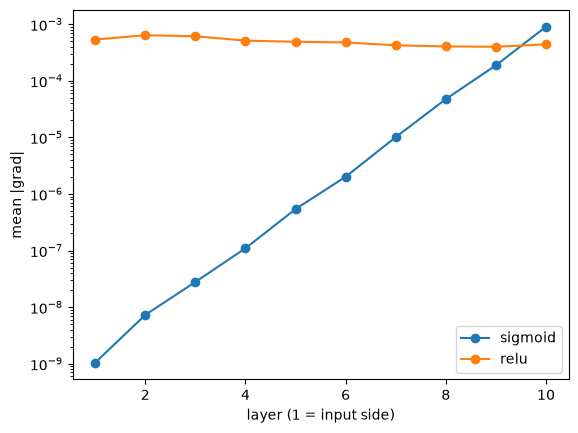

## 파트 3. 1에폭 학습해 보기

SGD (학습률 0.05, 배치 64) 로 1에폭. 1~2분 걸린다.

In [ ]:
def train_one_epoch(net, X, y, lr=0.05, batch=64, seed=0):
    g = torch.Generator().manual_seed(seed)
    opt = torch.optim.SGD(net.parameters(), lr=lr)
    for idx in torch.randperm(len(y), generator=g).split(batch):
        opt.zero_grad()
        nn.functional.cross_entropy(net(X[idx]), y[idx]).backward()
        opt.step()
    return net

for name, act in [("sigmoid", nn.Sigmoid()), ("relu", nn.ReLU()), ("leaky relu", nn.LeakyReLU(0.01)), ("gelu", nn.GELU())]:
    torch.manual_seed(0)
    net = train_one_epoch(make_net(act), Xtr, ytr)
    with torch.no_grad():
        acc = None  # TODO: test accuracy
    print(f"{name:10s}: test accuracy {acc:.3f}")

**예상 결과**

```
sigmoid   : test accuracy 0.098
relu      : test accuracy 0.940
leaky relu: test accuracy 0.940
gelu      : test accuracy 0.896
```

**확인 질문**
1. 파트 1 에서 Xavier 초기화가 ReLU 층에서 조금씩 줄어드는 이유는?
2. 파트 2 에서 시그모이드의 1층 기울기는 10층의 몇 분의 1인가? 슬라이드의 119만분의 1 과 비슷한가?
3. 파트 3 에서 시그모이드를 3층으로 줄이면 1에폭 정답률은 어떻게 되나? (`depth=3`)
4. (도전) 시그모이드 10층에서 학습률을 1.0 으로 키우면 나아지나? 기울기 소실을 학습률로 해결하기 어려운 이유는?

데이터 출처: LeCun, Cortes, Burges, MNIST handwritten digit database (torchvision).